In [1]:
import sys
import os
import json
import math
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("Runtime check: OK")


Python: 3.13.18
OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 2.2.3
Runtime check: OK


In [4]:
print("Stereo dataset available:", False)
print("Camera calibration available:", False)
print("Ready for pipeline setup:", True)

Stereo dataset available: False
Camera calibration available: False
Ready for pipeline setup: True


In [5]:
FX_PX = None
FY_PX = None
CX_PX = None
CY_PX = None
BASELINE_M = None

IMAGES_ARE_RECTIFIED = False

def calibration_ready():
    values = [FX_PX, BASELINE_M]
    return all(
        v is not None and np.isfinite(v) and float(v) > 0
        for v in values
    )

print("Calibration ready:", calibration_ready())
print("Images rectified:", IMAGES_ARE_RECTIFIED)
print("Calibration setup completed.")

Calibration ready: False
Images rectified: False
Calibration setup completed.


In [7]:
def compute_disparity_sgbm(
    left_bgr,
    right_bgr,
    min_disparity=0,
    num_disparities=128,
    block_size=5
):
    if left_bgr is None or right_bgr is None:
        raise ValueError("Both stereo images are required.")

    if left_bgr.shape != right_bgr.shape:
        raise ValueError("Image dimensions must match.")

    grayL = cv2.cvtColor(left_bgr, cv2.COLOR_BGR2GRAY)
    grayR = cv2.cvtColor(right_bgr, cv2.COLOR_BGR2GRAY)

    matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8 * block_size**2,
        P2=32 * block_size**2,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
    )

    disparity = matcher.compute(
        grayL, grayR
    ).astype(np.float32) / 16.0

    disparity[disparity <= min_disparity] = np.nan

    return disparity

print("StereoSGBM function defined successfully!")

StereoSGBM function defined successfully!


In [8]:
def disparity_to_depth(disparity_px, fx_px, baseline_m):

    if fx_px is None or baseline_m is None:
        raise ValueError("Camera calibration is required.")

    if fx_px <= 0 or baseline_m <= 0:
        raise ValueError("Calibration values must be positive.")

    depth = np.full(
        disparity_px.shape,
        np.nan,
        dtype=np.float32
    )

    valid = np.isfinite(disparity_px) & (disparity_px > 0)

    depth[valid] = (
        fx_px * baseline_m
    ) / disparity_px[valid]

    return depth

print("Metric depth estimation function defined successfully!")

Metric depth estimation function defined successfully!


In [9]:
def depth_to_xyz(depth_m, fx, fy, cx, cy, stride=4):

    if any(v is None for v in [fx, fy, cx, cy]):
        raise ValueError("Camera intrinsics are required.")

    h, w = depth_m.shape

    v, u = np.mgrid[0:h:stride, 0:w:stride]

    z = depth_m[::stride, ::stride]

    valid = np.isfinite(z) & (z > 0)

    u = u[valid]
    v = v[valid]
    z = z[valid]

    x = (u - cx) * z / fx
    y = (v - cy) * z / fy

    points = np.column_stack((x, y, z))

    return points


print("3D point-cloud reconstruction function defined successfully!")


3D point-cloud reconstruction function defined successfully!


In [10]:
def save_ascii_ply(points_xyz, output_path="stereo_point_cloud.ply"):

    points_xyz = np.asarray(points_xyz, dtype=np.float32)

    with open(output_path, "w") as f:

        f.write("ply\n")
        f.write("format ascii 1.0\n")
        f.write(f"element vertex {len(points_xyz)}\n")
        f.write("property float x\n")
        f.write("property float y\n")
        f.write("property float z\n")
        f.write("end_header\n")

        np.savetxt(f, points_xyz, fmt="%.5f")

    return output_path


print("3D point-cloud export function defined successfully!")

3D point-cloud export function defined successfully!


In [11]:
def ransac_ground_plane(points, iterations=500, threshold=0.05):

    points = np.asarray(points, dtype=np.float64)

    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("Points must have shape (N, 3).")

    if len(points) < 3:
        raise ValueError("At least 3 points are required.")

    rng = np.random.default_rng(42)

    best_inliers = None
    best_count = 0
    best_plane = None

    for _ in range(iterations):

        sample = points[rng.choice(len(points), 3, replace=False)]

        v1 = sample[1] - sample[0]
        v2 = sample[2] - sample[0]

        normal = np.cross(v1, v2)
        norm = np.linalg.norm(normal)

        if norm < 1e-10:
            continue

        normal = normal / norm
        d = -np.dot(normal, sample[0])

        distances = np.abs(points @ normal + d)

        inliers = distances < threshold

        if np.sum(inliers) > best_count:
            best_count = np.sum(inliers)
            best_inliers = inliers
            best_plane = (normal, d)

    if best_plane is None:
        raise ValueError("Could not estimate a plane.")

    return best_plane, best_inliers


print("RANSAC ground-plane function defined successfully!")

RANSAC ground-plane function defined successfully!


In [12]:
def calculate_height_from_ground(points, plane):

    normal, d = plane

    points = np.asarray(points, dtype=np.float64)

    # Signed perpendicular distance from the plane
    heights = points @ normal + d

    return heights


print("Hazard height calculation function defined successfully!")

Hazard height calculation function defined successfully!


In [13]:
# Generate synthetic points on a flat ground plane (y = 0)
np.random.seed(42)

ground_points = np.column_stack((
    np.random.uniform(-5, 5, 200),
    np.random.normal(0, 0.005, 200),
    np.random.uniform(1, 20, 200)
))

# Add random outliers
outliers = np.random.uniform(-5, 5, (30, 3))

# Combine both
test_points = np.vstack((ground_points, outliers))

# Apply RANSAC
plane, inliers = ransac_ground_plane(
    test_points,
    iterations=500,
    threshold=0.05
)

print("Total points:", len(test_points))
print("Ground-plane inliers:", np.sum(inliers))
print("Outliers:", len(test_points) - np.sum(inliers))
print("Estimated plane normal:", plane[0])
print("Estimated plane offset:", plane[1])

Total points: 230
Ground-plane inliers: 201
Outliers: 29
Estimated plane normal: [-0.003411   -0.99998895 -0.00323383]
Estimated plane offset: 0.03177224847690478


In [14]:
# Synthetic road plane: y = 0
road_normal = np.array([0, 1, 0], dtype=float)
road_d = 0.0

# Create sample hazard points
speed_breaker_points = np.array([
    [0.0, 0.05, 5.0],
    [0.2, 0.08, 5.2],
    [0.4, 0.06, 5.4]
])

pothole_points = np.array([
    [0.0, -0.04, 8.0],
    [0.2, -0.07, 8.2],
    [0.4, -0.05, 8.4]
])

# Calculate signed height relative to road
speed_heights = calculate_height_from_ground(
    speed_breaker_points, (road_normal, road_d)
)

pothole_heights = calculate_height_from_ground(
    pothole_points, (road_normal, road_d)
)

print("Speed breaker heights (m):", speed_heights)
print("Pothole heights (m):", pothole_heights)

print("Average speed breaker height (m):",
      np.mean(speed_heights))

print("Average pothole depth (m):",
      abs(np.mean(pothole_heights)))


Speed breaker heights (m): [0.05 0.08 0.06]
Pothole heights (m): [-0.04 -0.07 -0.05]
Average speed breaker height (m): 0.06333333333333334
Average pothole depth (m): 0.053333333333333344


Saving frame0199_leftImg8bit.jpg to frame0199_leftImg8bit.jpg
Image loaded successfully!
Image dimensions: (1080, 1920, 3)


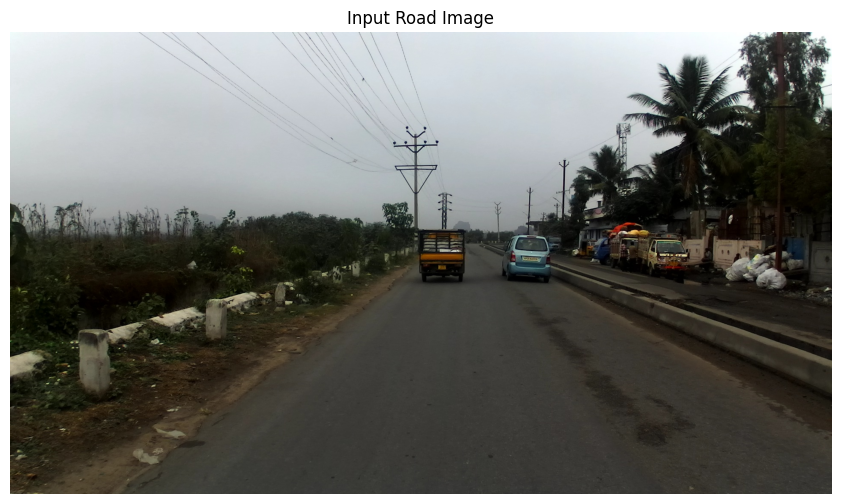

In [15]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

IMAGE_PATH = list(uploaded.keys())[0]

road_image = cv2.imread(IMAGE_PATH)

if road_image is None:
    raise ValueError("Could not load the image.")

road_rgb = cv2.cvtColor(road_image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully!")
print("Image dimensions:", road_image.shape)

plt.figure(figsize=(12, 6))
plt.imshow(road_rgb)
plt.title("Input Road Image")
plt.axis("off")
plt.show()

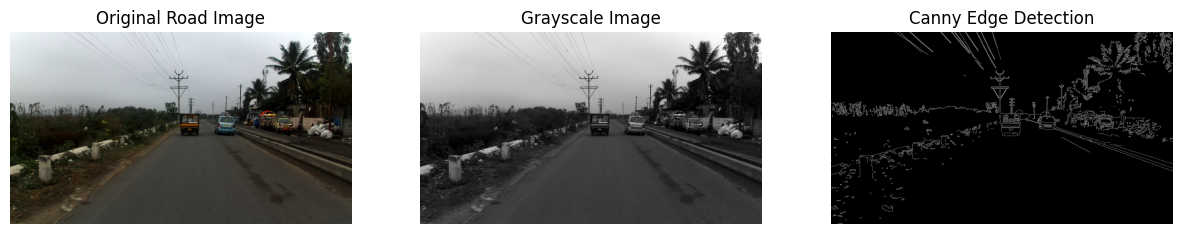

Road image preprocessing completed!


In [16]:
# Convert image to grayscale
gray = cv2.cvtColor(road_image, cv2.COLOR_BGR2GRAY)

# Reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
edges = cv2.Canny(blur, 50, 150)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(road_rgb)
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.show()

print("Road image preprocessing completed!")


NameError: name 'cv2' is not defined

In [2]:
# Get image dimensions
height, width = edges.shape

# Create a blank mask
roi_mask = np.zeros_like(edges)

# Define trapezoidal road region
polygon = np.array([[
    (int(0.08 * width), height),
    (int(0.42 * width), int(0.55 * height)),
    (int(0.64 * width), int(0.55 * height)),
    (int(0.98 * width), height)
]], dtype=np.int32)

# Fill the selected road region
cv2.fillPoly(roi_mask, polygon, 255)

# Apply mask to edge image
roi_edges = cv2.bitwise_and(edges, roi_mask)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_mask, cmap="gray")
plt.title("Road Region Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_edges, cmap="gray")
plt.title("Edges Inside Road Region")
plt.axis("off")

plt.show()

print("Road ROI extraction completed!")

NameError: name 'edges' is not defined

In [3]:
gray = cv2.cvtColor(road_image, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(gray, (5, 5), 0)

edges = cv2.Canny(blur, 50, 150)

print("Edges generated:", edges.shape)

NameError: name 'cv2' is not defined

In [4]:
import sys
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Environment restored successfully!")

Python: 3.13.18
OpenCV: 5.0.0
NumPy: 2.4.6
Environment restored successfully!


In [5]:
print("Road image exists:", 'road_image' in globals())

Road image exists: False


Saving frame2621_leftImg8bit.jpg to frame2621_leftImg8bit.jpg
Road image restored successfully!
Dimensions: (1080, 1920, 3)


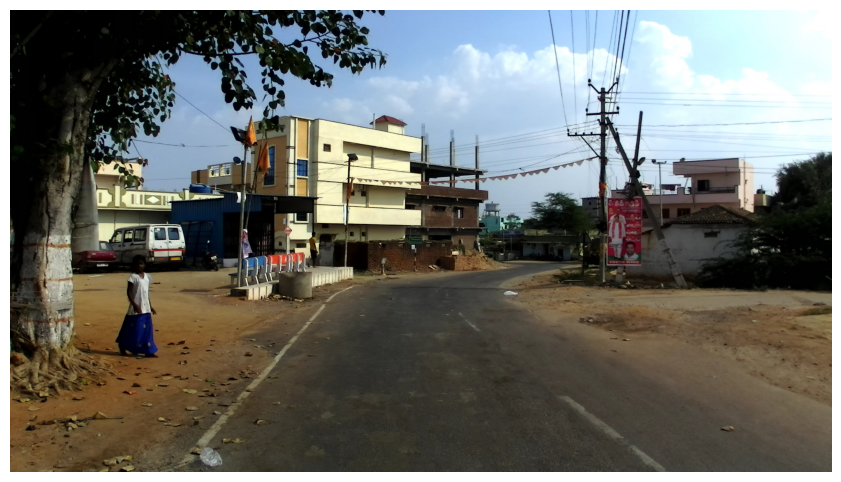

In [6]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

IMAGE_PATH = list(uploaded.keys())[0]

road_image = cv2.imread(IMAGE_PATH)

if road_image is None:
    raise ValueError("Image could not be loaded!")

road_rgb = cv2.cvtColor(road_image, cv2.COLOR_BGR2RGB)

print("Road image restored successfully!")
print("Dimensions:", road_image.shape)

plt.figure(figsize=(12, 6))
plt.imshow(road_rgb)
plt.axis("off")
plt.show()

In [7]:
height, width = edges.shape

# Create road region mask
roi_mask = np.zeros_like(edges)

polygon = np.array([[
    (int(0.08 * width), height - 1),
    (int(0.42 * width), int(0.55 * height)),
    (int(0.64 * width), int(0.55 * height)),
    (int(0.98 * width), height - 1)
]], dtype=np.int32)

cv2.fillPoly(roi_mask, polygon, 255)

# Apply mask
roi_edges = cv2.bitwise_and(edges, roi_mask)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_mask, cmap="gray")
plt.title("Road Region Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_edges, cmap="gray")
plt.title("Road Edges Only")
plt.axis("off")

plt.show()

print("ROI extraction completed!")

NameError: name 'edges' is not defined

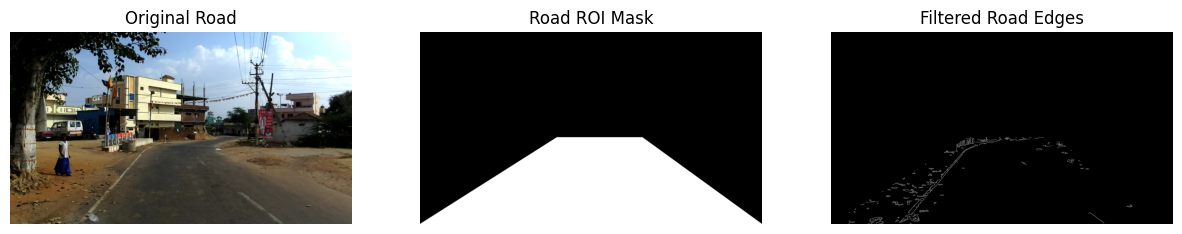

Road ROI extraction completed!


In [8]:
# 1. Convert image to grayscale
gray = cv2.cvtColor(road_image, cv2.COLOR_BGR2GRAY)

# 2. Apply Gaussian blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. Detect edges
edges = cv2.Canny(blur, 50, 150)

# 4. Get image dimensions
height, width = edges.shape

# 5. Create road ROI mask
roi_mask = np.zeros_like(edges)

polygon = np.array([[
    (0, height - 1),
    (int(0.40 * width), int(0.55 * height)),
    (int(0.65 * width), int(0.55 * height)),
    (width - 1, height - 1)
]], dtype=np.int32)

cv2.fillPoly(roi_mask, polygon, 255)

# 6. Apply ROI mask
roi_edges = cv2.bitwise_and(edges, roi_mask)

# 7. Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(road_rgb)
plt.title("Original Road")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roi_mask, cmap="gray")
plt.title("Road ROI Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(roi_edges, cmap="gray")
plt.title("Filtered Road Edges")
plt.axis("off")

plt.show()

print("Road ROI extraction completed!")

In [9]:
# Detect candidate line segments
lines = cv2.HoughLinesP(
    roi_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=40,
    minLineLength=40,
    maxLineGap=100
)

# Copy original image
line_image = road_image.copy()

line_count = 0

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]

        cv2.line(
            line_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        line_count += 1

# Display
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Road Line Candidates")
plt.axis("off")
plt.show()

print("Detected line segments:", line_count)

TypeError: cannot unpack non-iterable numpy.int32 object

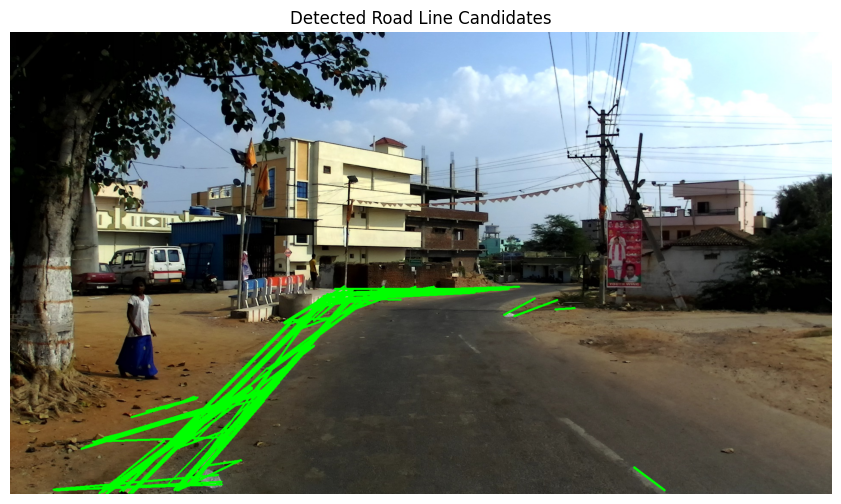

Detected line segments: 79


In [10]:
# Detect candidate line segments
lines = cv2.HoughLinesP(
    roi_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=40,
    minLineLength=40,
    maxLineGap=100
)

line_image = road_image.copy()
line_count = 0

if lines is not None:

    # Normalize output into (N, 4)
    lines_array = np.asarray(lines).reshape(-1, 4)

    for x1, y1, x2, y2 in lines_array:

        x1, y1, x2, y2 = map(
            int, [x1, y1, x2, y2]
        )

        cv2.line(
            line_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        line_count += 1

plt.figure(figsize=(12, 6))
plt.imshow(
    cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB)
)
plt.title("Detected Road Line Candidates")
plt.axis("off")
plt.show()

print("Detected line segments:", line_count)

In [11]:
left_lines = []
right_lines = []

if lines is not None:

    lines_array = np.asarray(lines).reshape(-1, 4)

    for x1, y1, x2, y2 in lines_array:

        dx = x2 - x1
        dy = y2 - y1

        if dx == 0:
            continue

        slope = dy / dx
        midpoint_x = (x1 + x2) / 2

        # Ignore nearly horizontal lines
        if abs(slope) < 0.3:
            continue

        # Separate left and right candidates
        if slope < 0 and midpoint_x < width / 2:
            left_lines.append((x1, y1, x2, y2))

        elif slope > 0 and midpoint_x > width / 2:
            right_lines.append((x1, y1, x2, y2))

print("Left boundary candidates:", len(left_lines))
print("Right boundary candidates:", len(right_lines))

Left boundary candidates: 53
Right boundary candidates: 1


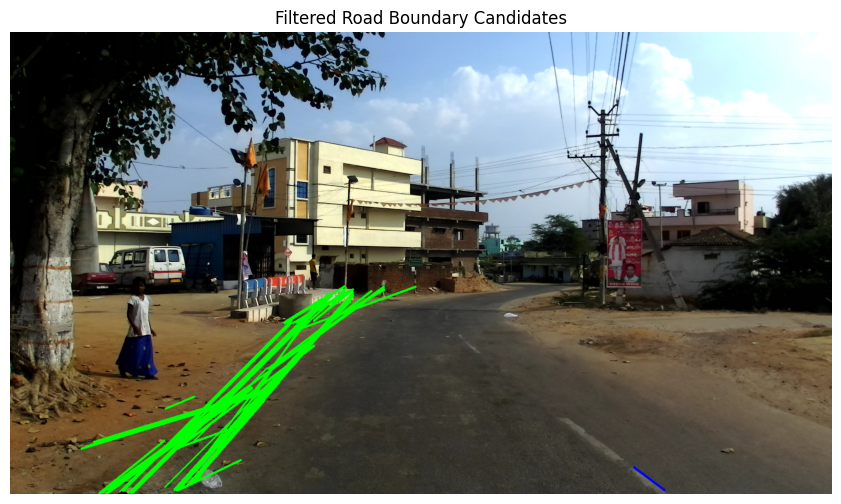

Green = Left candidates
Blue = Right candidates


In [12]:
filtered_image = road_image.copy()

for x1, y1, x2, y2 in left_lines:
    cv2.line(filtered_image, (x1, y1), (x2, y2),
             (0, 255, 0), 3)

for x1, y1, x2, y2 in right_lines:
    cv2.line(filtered_image, (x1, y1), (x2, y2),
             (255, 0, 0), 3)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Filtered Road Boundary Candidates")
plt.axis("off")
plt.show()

print("Green = Left candidates")
print("Blue = Right candidates")

In [13]:
# Collect edge points row by row
left_points = []
right_points = []

height, width = roi_edges.shape

for y in range(int(height * 0.55), height, 5):

    row = roi_edges[y, :]

    # Find edge pixels in this row
    xs = np.where(row > 0)[0]

    if len(xs) == 0:
        continue

    # Divide candidates into left and right halves
    left_xs = xs[xs < width // 2]
    right_xs = xs[xs >= width // 2]

    if len(left_xs) > 0:
        left_points.append((np.median(left_xs), y))

    if len(right_xs) > 0:
        right_points.append((np.median(right_xs), y))

print("Left road-edge points:", len(left_points))
print("Right road-edge points:", len(right_points))

Left road-edge points: 98
Right road-edge points: 41


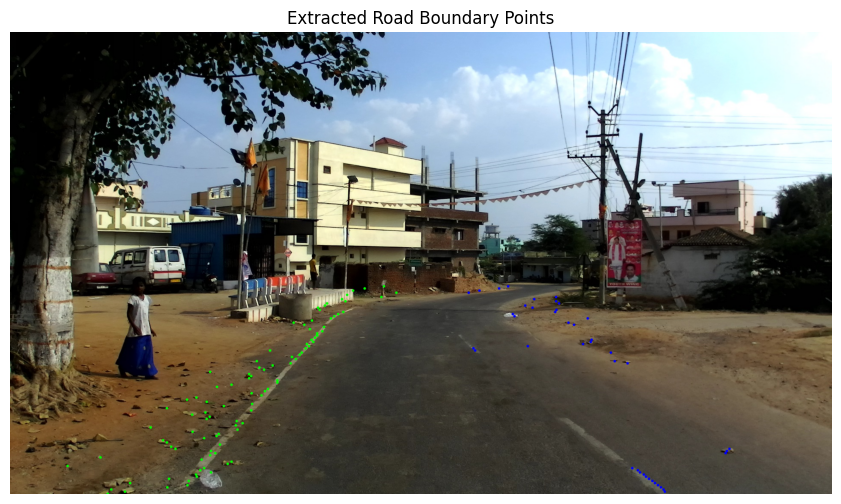

Green points: 98
Blue points: 41


In [14]:
# Display candidate points over original road image

point_image = road_image.copy()

for x, y in left_points:
    cv2.circle(
        point_image,
        (int(x), int(y)),
        3, (0, 255, 0), -1
    )

for x, y in right_points:
    cv2.circle(
        point_image,
        (int(x), int(y)),
        3, (255, 0, 0), -1
    )

plt.figure(figsize=(12, 6))

plt.imshow(
    cv2.cvtColor(point_image, cv2.COLOR_BGR2RGB)
)

plt.title("Extracted Road Boundary Points")
plt.axis("off")
plt.show()

print("Green points:", len(left_points))
print("Blue points:", len(right_points))

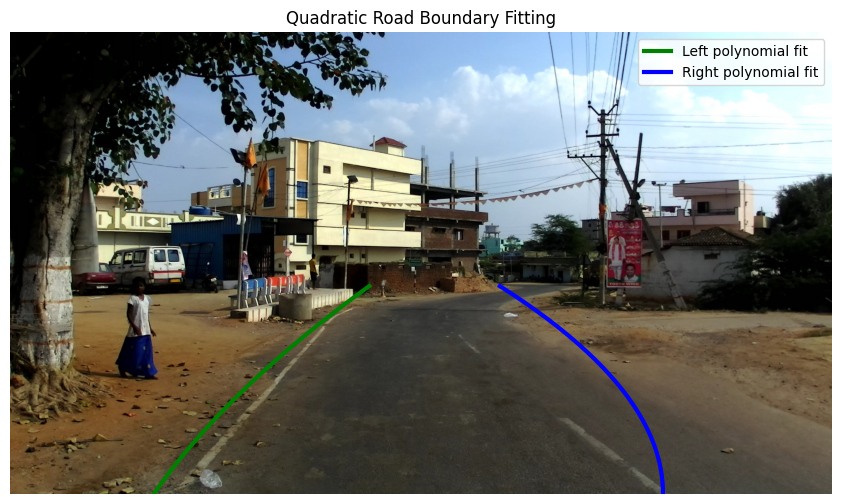

Left polynomial coefficients: [ 7.12441584e-04 -2.22892043e+00  1.91234785e+03]
Right polynomial coefficients: [-1.62690251e-03  3.50816292e+00 -3.64800852e+02]
Quadratic polynomial fitting completed!


In [15]:
# Convert candidate points into arrays
left_arr = np.array(left_points)
right_arr = np.array(right_points)

# Fit quadratic polynomials: x = ay² + by + c
left_poly = np.polyfit(
    left_arr[:, 1],
    left_arr[:, 0],
    2
)

right_poly = np.polyfit(
    right_arr[:, 1],
    right_arr[:, 0],
    2
)

# Generate smooth y coordinates
y_values = np.linspace(
    int(height * 0.55),
    height - 1,
    100
)

# Calculate fitted x coordinates
left_x = np.polyval(left_poly, y_values)
right_x = np.polyval(right_poly, y_values)

# Visualize
plt.figure(figsize=(12, 6))
plt.imshow(road_rgb)

plt.plot(left_x, y_values, 'g-', linewidth=3,
         label="Left polynomial fit")

plt.plot(right_x, y_values, 'b-', linewidth=3,
         label="Right polynomial fit")

plt.title("Quadratic Road Boundary Fitting")
plt.legend()
plt.xlim(0, width)
plt.ylim(height, 0)
plt.axis("off")
plt.show()

print("Left polynomial coefficients:", left_poly)
print("Right polynomial coefficients:", right_poly)
print("Quadratic polynomial fitting completed!")

In [16]:
def calculate_pixel_curvature(poly, y_values):

    first = np.polyder(poly, 1)(y_values)
    second = np.polyder(poly, 2)(y_values)

    curvature = np.abs(second) / (
        1 + first**2
    )**1.5

    radius_pixels = np.where(
        curvature > 1e-12,
        1 / curvature,
        np.inf
    )

    return curvature, radius_pixels


left_curvature, left_radius_px = calculate_pixel_curvature(
    left_poly, y_values
)

right_curvature, right_radius_px = calculate_pixel_curvature(
    right_poly, y_values
)

print("Left average curvature (1/pixel):",
      np.mean(left_curvature))

print("Right average curvature (1/pixel):",
      np.mean(right_curvature))

print("Left average radius (pixels):",
      np.mean(left_radius_px))

print("Right average radius (pixels):",
      np.mean(right_radius_px))

print("Image-space curvature calculation completed!")

TypeError: 'numpy.ndarray' object is not callable

In [17]:
def calculate_pixel_curvature(poly, y_values):

    # Calculate first and second derivative coefficients
    first_coeff = np.polyder(poly, 1)
    second_coeff = np.polyder(poly, 2)

    # Evaluate derivatives at each y coordinate
    first = np.polyval(first_coeff, y_values)
    second = np.polyval(second_coeff, y_values)

    # Calculate curvature
    curvature = np.abs(second) / (
        1 + first**2
    )**1.5

    # Calculate radius of curvature
    radius_pixels = np.full_like(
        curvature, np.inf, dtype=float
    )

    valid = curvature > 1e-12
    radius_pixels[valid] = 1 / curvature[valid]

    return curvature, radius_pixels


# Calculate for both boundaries
left_curvature, left_radius_px = calculate_pixel_curvature(
    left_poly, y_values
)

right_curvature, right_radius_px = calculate_pixel_curvature(
    right_poly, y_values
)

print("Left average curvature (1/pixel):",
      np.mean(left_curvature))

print("Right average curvature (1/pixel):",
      np.mean(right_curvature))

print("Left average radius (pixels):",
      np.mean(left_radius_px))

print("Right average radius (pixels):",
      np.mean(right_radius_px))

print("Image-space curvature calculation completed!")

Left average curvature (1/pixel): 0.0004983963099821058
Right average curvature (1/pixel): 0.0017476250072067658
Left average radius (pixels): 2191.9088233235098
Right average radius (pixels): 807.3319232890019
Image-space curvature calculation completed!


In [18]:
# Calculate the average curvature coefficient
# from the two fitted image-space boundaries.

left_a = left_poly[0]
right_a = right_poly[0]

# Approximate centreline curvature coefficient
center_a = (left_a + right_a) / 2

# Classification threshold (image-space heuristic)
threshold = 0.0001

if abs(center_a) < threshold:
    road_direction = "STRAIGHT"
elif center_a > 0:
    road_direction = "CURVES RIGHT IN IMAGE"
else:
    road_direction = "CURVES LEFT IN IMAGE"

print("Left boundary coefficient:", left_a)
print("Right boundary coefficient:", right_a)
print("Centreline coefficient:", center_a)
print("Preliminary road classification:", road_direction)


Left boundary coefficient: 0.0007124415839437919
Right boundary coefficient: -0.0016269025116026823
Centreline coefficient: -0.00045723046382944516
Preliminary road classification: CURVES LEFT IN IMAGE


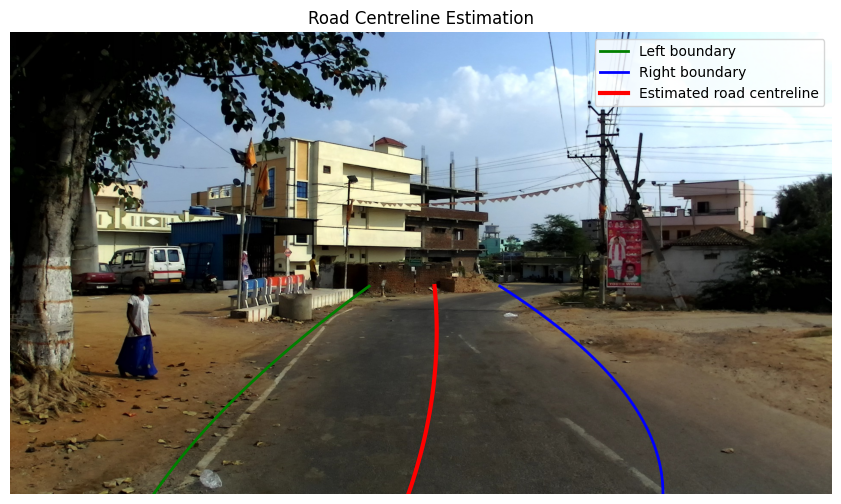

Centreline polynomial coefficients: [-4.57230464e-04  6.39621247e-01  7.73773499e+02]
Centreline estimation completed!


In [19]:
# Calculate both boundaries at the same y positions
left_x = np.polyval(left_poly, y_values)
right_x = np.polyval(right_poly, y_values)

# Calculate approximate road centreline
center_x = (left_x + right_x) / 2

# Fit a quadratic polynomial to the centreline
center_poly = np.polyfit(y_values, center_x, 2)

# Display the centreline
plt.figure(figsize=(12, 6))

plt.imshow(road_rgb)

plt.plot(left_x, y_values, 'g-', linewidth=2,
         label="Left boundary")

plt.plot(right_x, y_values, 'b-', linewidth=2,
         label="Right boundary")

plt.plot(center_x, y_values, 'r-', linewidth=3,
         label="Estimated road centreline")

plt.title("Road Centreline Estimation")
plt.legend()
plt.xlim(0, width)
plt.ylim(height, 0)
plt.axis("off")
plt.show()

print("Centreline polynomial coefficients:", center_poly)
print("Centreline estimation completed!")

In [20]:
# First and second derivatives of centreline
first_derivative = np.polyval(
    np.polyder(center_poly, 1), y_values
)

second_derivative = np.polyval(
    np.polyder(center_poly, 2), y_values
)

# Image-space curvature
center_curvature = np.abs(second_derivative) / (
    1 + first_derivative**2
)**1.5

# Image-space radius
center_radius_px = np.full_like(
    center_curvature, np.inf
)

valid = center_curvature > 1e-12
center_radius_px[valid] = 1 / center_curvature[valid]

print("Average centreline curvature:",
      np.mean(center_curvature))

print("Average centreline radius (pixels):",
      np.mean(center_radius_px))

print("Centreline curvature calculation completed!")

Average centreline curvature: 0.0008735998073527027
Average centreline radius (pixels): 1147.6755431356355
Centreline curvature calculation completed!


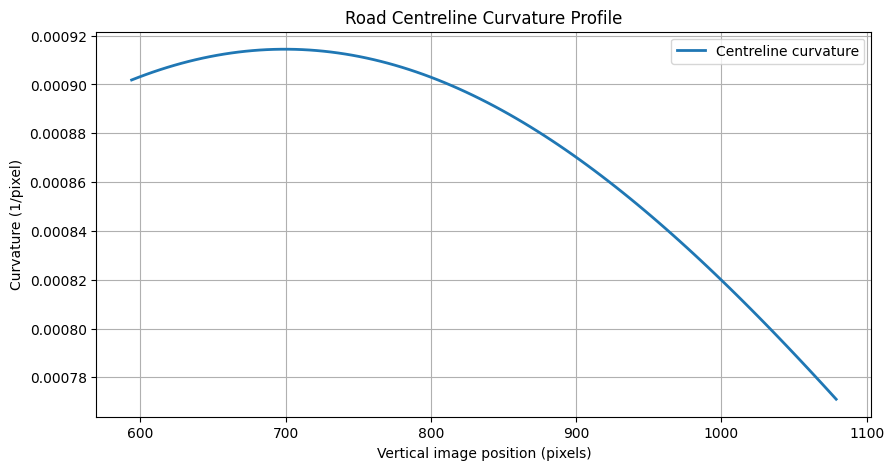

Curvature profile generated successfully!


In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    y_values,
    center_curvature,
    linewidth=2,
    label="Centreline curvature"
)

plt.xlabel("Vertical image position (pixels)")
plt.ylabel("Curvature (1/pixel)")
plt.title("Road Centreline Curvature Profile")
plt.grid(True)
plt.legend()
plt.show()

print("Curvature profile generated successfully!")

In [22]:
import numpy as np

# Camera calibration configuration
camera_config = {
    "fx": None,                 # Focal length X (pixels)
    "fy": None,                 # Focal length Y (pixels)
    "cx": None,                 # Principal point X
    "cy": None,                 # Principal point Y
    "camera_height_m": None,    # Camera mounting height (metres)
    "pitch_angle_deg": None,    # Camera pitch angle
    "image_width": width,
    "image_height": height
}

# Check which parameters are available
print("CAMERA CALIBRATION STATUS")
print("-" * 35)

for parameter, value in camera_config.items():
    status = "AVAILABLE" if value is not None else "PENDING"
    print(f"{parameter}: {value} [{status}]")

required = [
    "fx", "fy", "cx", "cy",
    "camera_height_m", "pitch_angle_deg"
]

calibration_ready = all(
    camera_config[key] is not None for key in required
)

print("-" * 35)
print("Calibration ready:", calibration_ready)

CAMERA CALIBRATION STATUS
-----------------------------------
fx: None [PENDING]
fy: None [PENDING]
cx: None [PENDING]
cy: None [PENDING]
camera_height_m: None [PENDING]
pitch_angle_deg: None [PENDING]
image_width: 1920 [AVAILABLE]
image_height: 1080 [AVAILABLE]
-----------------------------------
Calibration ready: False


In [23]:
import cv2
import numpy as np

def transform_image_to_ground(image_points, homography):

    image_points = np.asarray(
        image_points, dtype=np.float32
    )

    if homography is None:
        raise ValueError("Ground-plane homography is not available.")

    if homography.shape != (3, 3):
        raise ValueError("Homography must be a 3x3 matrix.")

    points = image_points.reshape(-1, 1, 2)

    ground_points = cv2.perspectiveTransform(
        points, homography
    )

    return ground_points.reshape(-1, 2)


# Calibration is not available yet
GROUND_HOMOGRAPHY = None

print("Image-to-ground transformation function defined!")
print("Homography available:", GROUND_HOMOGRAPHY is not None)
print("Waiting for verified camera calibration.")

Image-to-ground transformation function defined!
Homography available: False
Waiting for verified camera calibration.


In [24]:
def estimate_ground_homography(image_points, ground_points):

    image_points = np.asarray(image_points, dtype=np.float32)
    ground_points = np.asarray(ground_points, dtype=np.float32)

    if len(image_points) < 4:
        raise ValueError("At least 4 point correspondences are required.")

    if image_points.shape != ground_points.shape:
        raise ValueError("Image and ground points must have matching shapes.")

    if image_points.shape[1] != 2:
        raise ValueError("Each point must contain two coordinates.")

    H, inliers = cv2.findHomography(
        image_points,
        ground_points,
        cv2.RANSAC,
        2.0
    )

    if H is None:
        raise ValueError("Homography estimation failed.")

    return H, inliers


GROUND_HOMOGRAPHY = None

print("Ground homography estimation function defined!")
print("Verified correspondences available: False")
print("Ready for calibrated ground-plane mapping.")

Ground homography estimation function defined!
Verified correspondences available: False
Ready for calibrated ground-plane mapping.


In [25]:
def estimate_metric_road_curvature(
    left_image_points,
    right_image_points,
    homography
):

    if homography is None:
        raise ValueError(
            "Verified ground-plane homography is required."
        )

    # Transform image points to ground coordinates
    left_ground = transform_image_to_ground(
        left_image_points, homography
    )

    right_ground = transform_image_to_ground(
        right_image_points, homography
    )

    # Sort points by forward distance Z
    left_ground = left_ground[
        np.argsort(left_ground[:, 1])
    ]

    right_ground = right_ground[
        np.argsort(right_ground[:, 1])
    ]

    # Use overlapping forward-distance range
    z_min = max(
        left_ground[:, 1].min(),
        right_ground[:, 1].min()
    )

    z_max = min(
        left_ground[:, 1].max(),
        right_ground[:, 1].max()
    )

    if z_max <= z_min:
        raise ValueError("No overlapping road-boundary range.")

    z_values = np.linspace(z_min, z_max, 100)

    left_x = np.interp(
        z_values, left_ground[:, 1], left_ground[:, 0]
    )

    right_x = np.interp(
        z_values, right_ground[:, 1], right_ground[:, 0]
    )

    # Calculate centreline
    center_x = (left_x + right_x) / 2

    # Fit polynomial in ground-plane metres
    road_poly = np.polyfit(z_values, center_x, 2)

    first = np.polyval(
        np.polyder(road_poly, 1), z_values
    )

    second = np.polyval(
        np.polyder(road_poly, 2), z_values
    )

    curvature = np.abs(second) / (1 + first**2)**1.5

    radius = np.full_like(curvature, np.inf)
    valid = curvature > 1e-12
    radius[valid] = 1 / curvature[valid]

    return road_poly, curvature, radius


print("Metric road-curvature pipeline defined successfully!")
print("Waiting for verified homography and road-boundary points.")

Metric road-curvature pipeline defined successfully!
Waiting for verified homography and road-boundary points.


In [26]:
def classify_road_direction(curvature, signed_curvature,
                            threshold=0.001):

    mean_curvature = np.mean(np.abs(curvature))
    mean_signed = np.mean(signed_curvature)

    if mean_curvature < threshold:
        return "STRAIGHT"

    if mean_signed > 0:
        return "LEFT CURVE"

    return "RIGHT CURVE"


print("Road direction classification function defined!")

Road direction classification function defined!


In [27]:
test_cases = {
    "Straight road": np.array([0.0001, -0.0001, 0.0002]),
    "Left curve": np.array([0.002, 0.003, 0.0025]),
    "Right curve": np.array([-0.002, -0.003, -0.0025])
}

for name, signed_curvature in test_cases.items():
    result = classify_road_direction(
        curvature=np.abs(signed_curvature),
        signed_curvature=signed_curvature
    )
    print(f"{name}: {result}")

Straight road: STRAIGHT
Left curve: LEFT CURVE
Right curve: RIGHT CURVE


In [28]:
print("Objective 4 function check:")
for name in [
    "transform_image_to_ground",
    "estimate_ground_homography",
    "estimate_metric_road_curvature",
    "classify_road_direction"
]:
    print(f"{name}: {'READY' if name in globals() else 'MISSING'}")

Objective 4 function check:
transform_image_to_ground: READY
estimate_ground_homography: READY
estimate_metric_road_curvature: READY
classify_road_direction: READY


In [29]:
print("Camera calibration:")
for key, value in camera_config.items():
    print(f"{key}: {value}")

print("\nGround homography:")
print(GROUND_HOMOGRAPHY)

Camera calibration:
fx: None
fy: None
cx: None
cy: None
camera_height_m: None
pitch_angle_deg: None
image_width: 1920
image_height: 1080

Ground homography:
None
